# BRSR ESG KPI Analysis
Visualization of extracted BRSR data across 5 Indian banks (AXIS, HDFC, ICICI, KOTAK, PNB) for FY2023-24, FY2024-25, FY2025-26.

In [1]:
import json
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np
from pathlib import Path

ROOT = Path('..')
plt.style.use('seaborn-v0_8-whitegrid')
COMPANY_ORDER = ['AXIS', 'HDFC', 'ICICI', 'KOTAK', 'PNB']
FY_ORDER = ['2023-2024', '2024-2025', '2025-2026']
COLORS = {'AXIS': '#1f77b4', 'HDFC': '#ff7f0e', 'ICICI': '#2ca02c', 'KOTAK': '#d62728', 'PNB': '#9467bd'}

## Load Data

In [2]:
# Load KPI data
with open(ROOT / 'data' / 'kpis.json') as f:
    kpi_records = json.load(f)
kpi_df = pd.DataFrame(kpi_records)
print(f'Loaded {len(kpi_df)} KPI records for {kpi_df["company"].nunique()} companies')
kpi_df.head(10)

Loaded 75 KPI records for 5 companies


,company,fy,kpi,value,prior_year_value,unit
0,AXIS,2023-2024,ghg_intensity,0.126000,0.210000,g CO
1,AXIS,2023-2024,water_intensity,9.000000,0.000147,KL/INR crore
2,AXIS,2023-2024,employee_turnover_rate,28.800000,34.800000,%
3,AXIS,2023-2024,gender_pay_gap,NaN,NaN,NaN
4,AXIS,2023-2024,safety_incident_rate,NaN,NaN,per million person-hours
5,AXIS,2024-2025,ghg_intensity,0.097000,0.126000,g CO
6,AXIS,2024-2025,water_intensity,0.000124,0.000147,KL/INR crore
7,AXIS,2024-2025,employee_turnover_rate,25.500000,28.800000,%
8,AXIS,2024-2025,gender_pay_gap,-0.008811,NaN,fraction (M-F)/M
9,AXIS,2024-2025,safety_incident_rate,0.000000,NaN,per million person-hours


In [3]:
# Load extracted data for completion rates
extracted = {}
for path in sorted((ROOT / 'data' / 'extracted').glob('*.json')):
    with open(path) as f:
        d = json.load(f)
    extracted[(d['company'], d['fy'])] = d
print(f'Loaded {len(extracted)} extracted reports')

Loaded 15 extracted reports


## Deliverable 2: Cross-Company KPI Benchmark (Bar Chart)

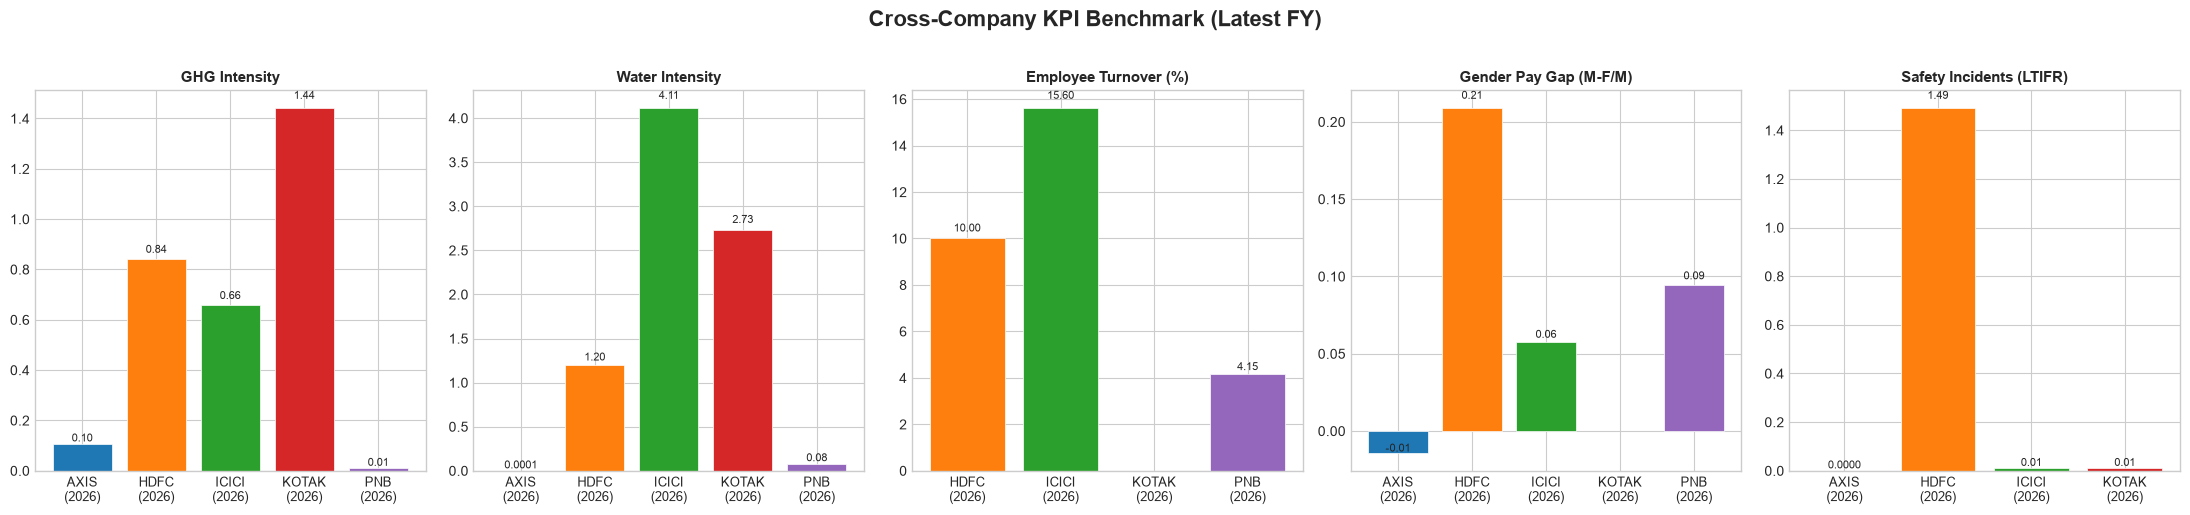

Saved: data/output/benchmark_chart.png


In [4]:
kpi_labels = {
    'ghg_intensity': 'GHG Intensity',
    'water_intensity': 'Water Intensity',
    'employee_turnover_rate': 'Employee Turnover (%)',
    'gender_pay_gap': 'Gender Pay Gap (M-F/M)',
    'safety_incident_rate': 'Safety Incidents (LTIFR)',
}

fig, axes = plt.subplots(1, 5, figsize=(22, 5), sharey=False)
fig.suptitle('Cross-Company KPI Benchmark (Latest FY)', fontsize=16, fontweight='bold', y=1.02)

for ax, (kpi, label) in zip(axes, kpi_labels.items()):
    latest = kpi_df[kpi_df['kpi'] == kpi].copy()
    # Get latest FY per company
    latest_fy = {}
    for company in COMPANY_ORDER:
        company_data = latest[latest['company'] == company]
        fys = sorted(company_data['fy'].dropna().unique(), reverse=True)
        latest_fy[company] = fys[0] if fys else None
    
    vals = []
    labels_list = []
    colors = []
    for company in COMPANY_ORDER:
        fy = latest_fy.get(company)
        if fy:
            v = latest[(latest['company'] == company) & (latest['fy'] == fy)]['value'].values
            if len(v) > 0 and v[0] is not None:
                vals.append(v[0])
                labels_list.append(f"{company}\n({fy[-4:]})")
                colors.append(COLORS[company])
    
    bars = ax.bar(labels_list, vals, color=colors, edgecolor='white', linewidth=0.5)
    ax.set_title(label, fontsize=11, fontweight='bold')
    ax.tick_params(axis='x', labelsize=9)
    
    # Add value labels on bars
    for bar, v in zip(bars, vals):
        fmt = f'{v:.4f}' if abs(v) < 0.01 else f'{v:.2f}'
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + bar.get_height()*0.02,
                fmt, ha='center', va='bottom', fontsize=8)

plt.tight_layout()
plt.savefig(ROOT / 'data' / 'output' / 'benchmark_chart.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved: data/output/benchmark_chart.png')

## Deliverable 3: Time-Series per KPI (Line Charts)

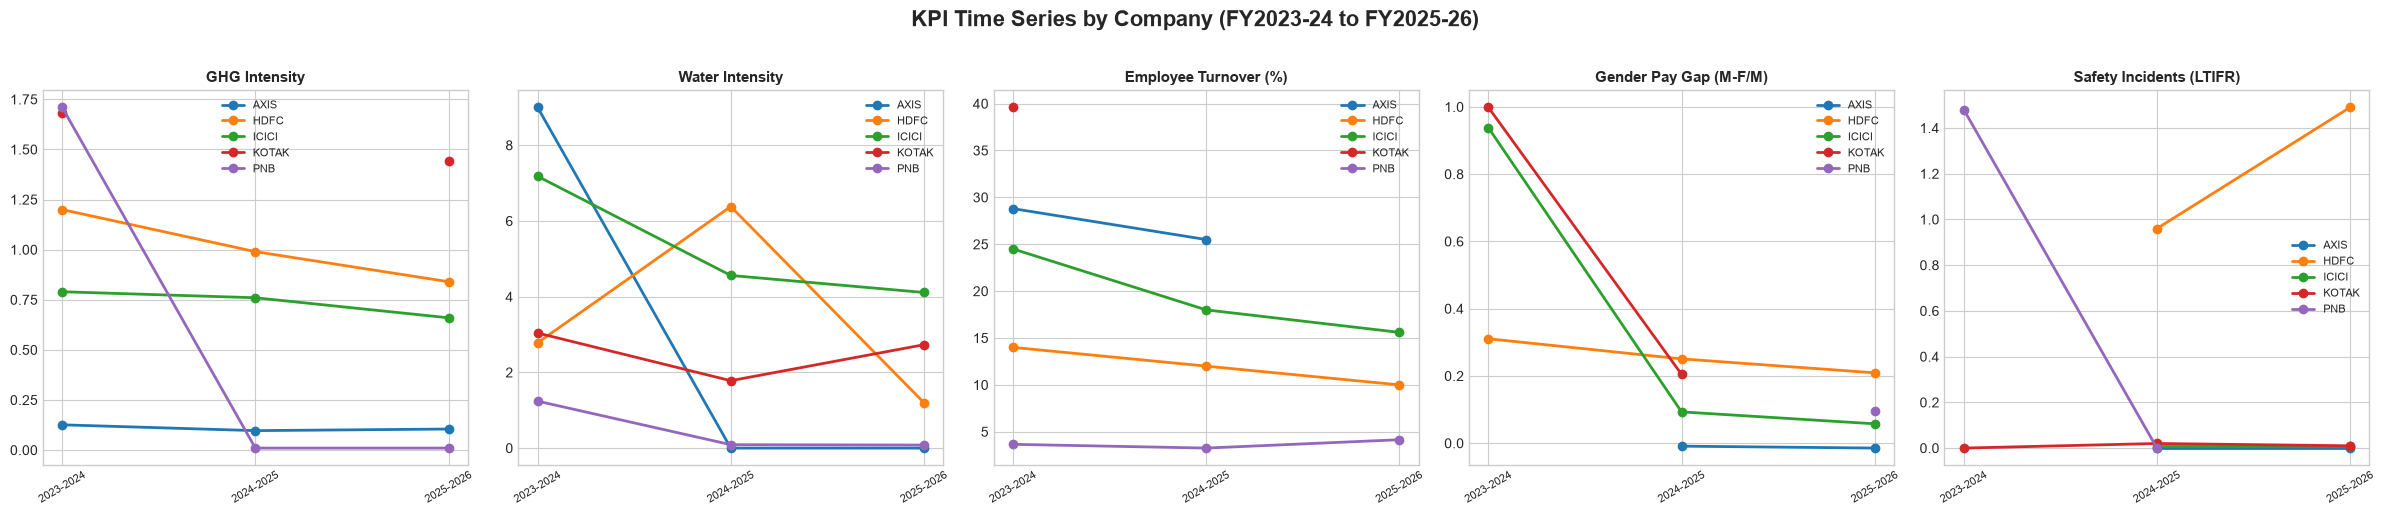

Saved: data/output/timeseries_chart.png


In [5]:
fig, axes = plt.subplots(1, 5, figsize=(24, 5), sharey=False)
fig.suptitle('KPI Time Series by Company (FY2023-24 to FY2025-26)', fontsize=16, fontweight='bold', y=1.02)

for ax, (kpi, label) in zip(axes, kpi_labels.items()):
    for company in COMPANY_ORDER:
        data = kpi_df[(kpi_df['company'] == company) & (kpi_df['kpi'] == kpi)].sort_values('fy')
        fys = data['fy'].values
        vals = data['value'].values
        # Filter out None
        mask = [v is not None for v in vals]
        if any(mask):
            ax.plot(np.array(fys)[mask], np.array(vals)[mask],
                    marker='o', label=company, color=COLORS[company], linewidth=2, markersize=6)
    
    ax.set_title(label, fontsize=11, fontweight='bold')
    ax.tick_params(axis='x', labelsize=8, rotation=30)
    ax.legend(fontsize=8, loc='best')

plt.tight_layout()
plt.savefig(ROOT / 'data' / 'output' / 'timeseries_chart.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved: data/output/timeseries_chart.png')

## Deliverable 4: Essential vs Leadership Completion Rate

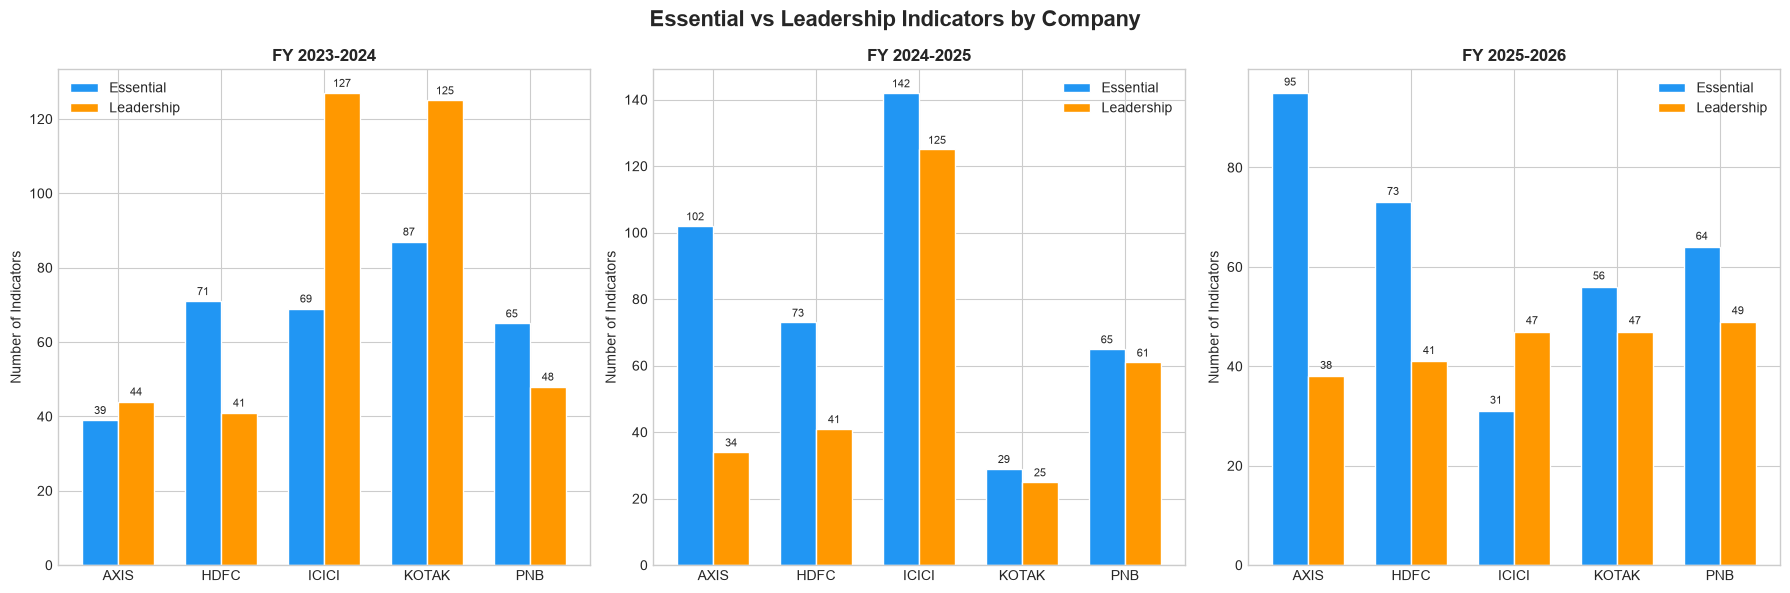

Saved: data/output/completion_chart.png


In [6]:
# Build completion data
completion_rows = []
for (company, fy), rec in sorted(extracted.items()):
    for p in rec.get('principles', []):
        completion_rows.append({
            'Company': company, 'FY': fy,
            'Principle': f"P{p['principle_no']}",
            'Essential': len(p.get('essential_indicators', [])),
            'Leadership': len(p.get('leadership_indicators', [])),
        })
comp_df = pd.DataFrame(completion_rows)

# Summary: total essential + leadership per company-FY
summary = comp_df.groupby(['Company', 'FY']).agg({'Essential': 'sum', 'Leadership': 'sum'}).reset_index()
summary['Total'] = summary['Essential'] + summary['Leadership']

fig, axes = plt.subplots(1, 3, figsize=(18, 6))
fig.suptitle('Essential vs Leadership Indicators by Company', fontsize=16, fontweight='bold')

for ax, fy in zip(axes, FY_ORDER):
    fy_data = summary[summary['FY'] == fy].set_index('Company').reindex(COMPANY_ORDER)
    if fy_data.empty or fy_data['Essential'].isna().all():
        ax.set_title(f'FY {fy} (No data)')
        continue
    
    x = np.arange(len(COMPANY_ORDER))
    w = 0.35
    bars1 = ax.bar(x - w/2, fy_data['Essential'], w, label='Essential', color='#2196F3', edgecolor='white')
    bars2 = ax.bar(x + w/2, fy_data['Leadership'], w, label='Leadership', color='#FF9800', edgecolor='white')
    
    ax.set_xticks(x)
    ax.set_xticklabels(COMPANY_ORDER, fontsize=10)
    ax.set_title(f'FY {fy}', fontsize=12, fontweight='bold')
    ax.set_ylabel('Number of Indicators')
    ax.legend()
    
    # Value labels
    for bars in [bars1, bars2]:
        for bar in bars:
            h = bar.get_height()
            if h > 0:
                ax.text(bar.get_x() + bar.get_width()/2, h + 1, f'{int(h)}',
                        ha='center', va='bottom', fontsize=8)

plt.tight_layout()
plt.savefig(ROOT / 'data' / 'output' / 'completion_chart.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved: data/output/completion_chart.png')

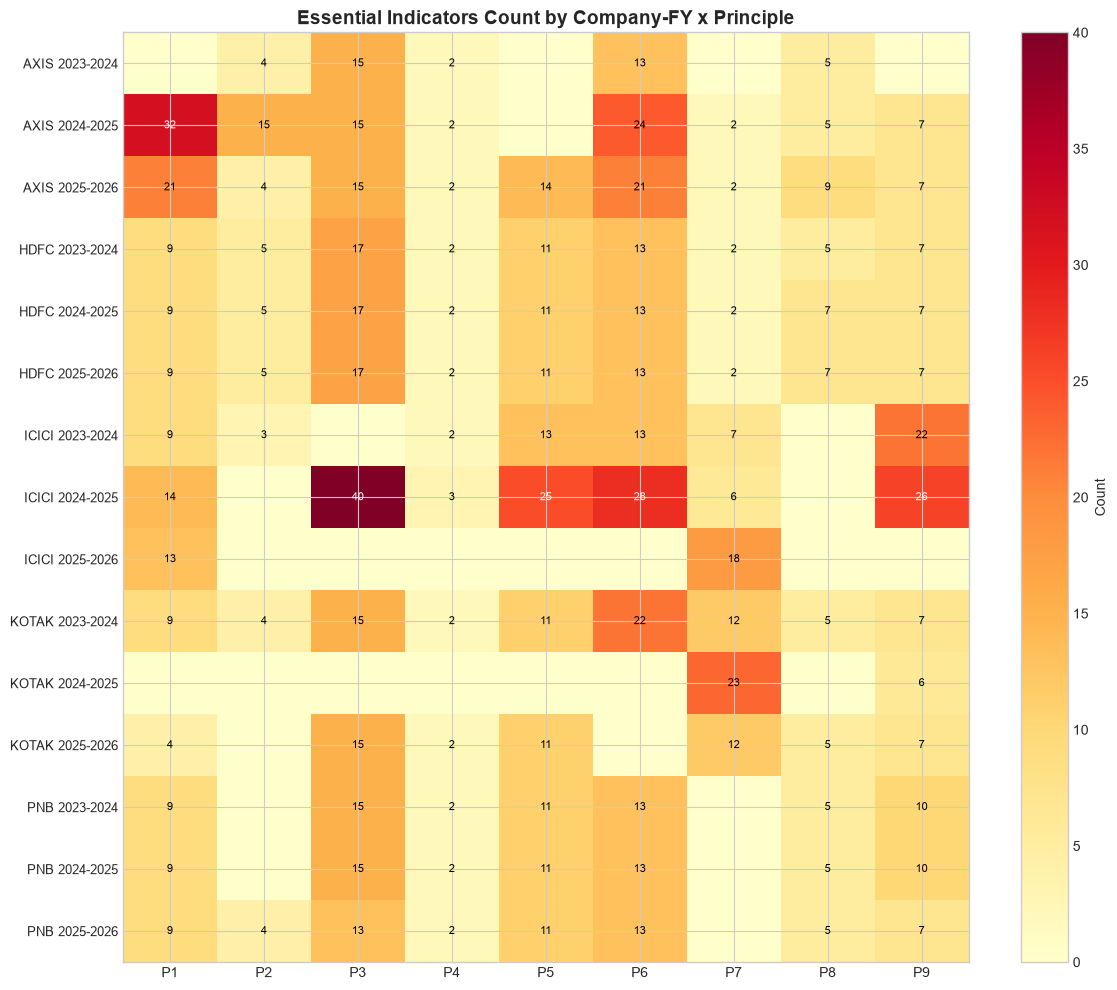

Saved: data/output/heatmap_essential.png


In [7]:
# Per-principle breakdown (heatmap-style)
pivot = comp_df.pivot_table(index=['Company', 'FY'], columns='Principle',
                            values='Essential', aggfunc='sum', fill_value=0)
pivot = pivot.reindex(pd.MultiIndex.from_product([COMPANY_ORDER, FY_ORDER]))

fig, ax = plt.subplots(figsize=(12, 10))
im = ax.imshow(pivot.values, cmap='YlOrRd', aspect='auto')
ax.set_xticks(range(len(pivot.columns)))
ax.set_xticklabels(pivot.columns, fontsize=10)
ax.set_yticks(range(len(pivot.index)))
ax.set_yticklabels([f'{c} {fy}' for c, fy in pivot.index], fontsize=9)
ax.set_title('Essential Indicators Count by Company-FY x Principle', fontsize=14, fontweight='bold')
plt.colorbar(im, ax=ax, label='Count')

# Annotate cells
for i in range(pivot.shape[0]):
    for j in range(pivot.shape[1]):
        v = pivot.values[i, j]
        if v > 0:
            ax.text(j, i, str(int(v)), ha='center', va='center', fontsize=8,
                    color='white' if v > pivot.values.max()*0.6 else 'black')

plt.tight_layout()
plt.savefig(ROOT / 'data' / 'output' / 'heatmap_essential.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved: data/output/heatmap_essential.png')

## Data Availability Matrix

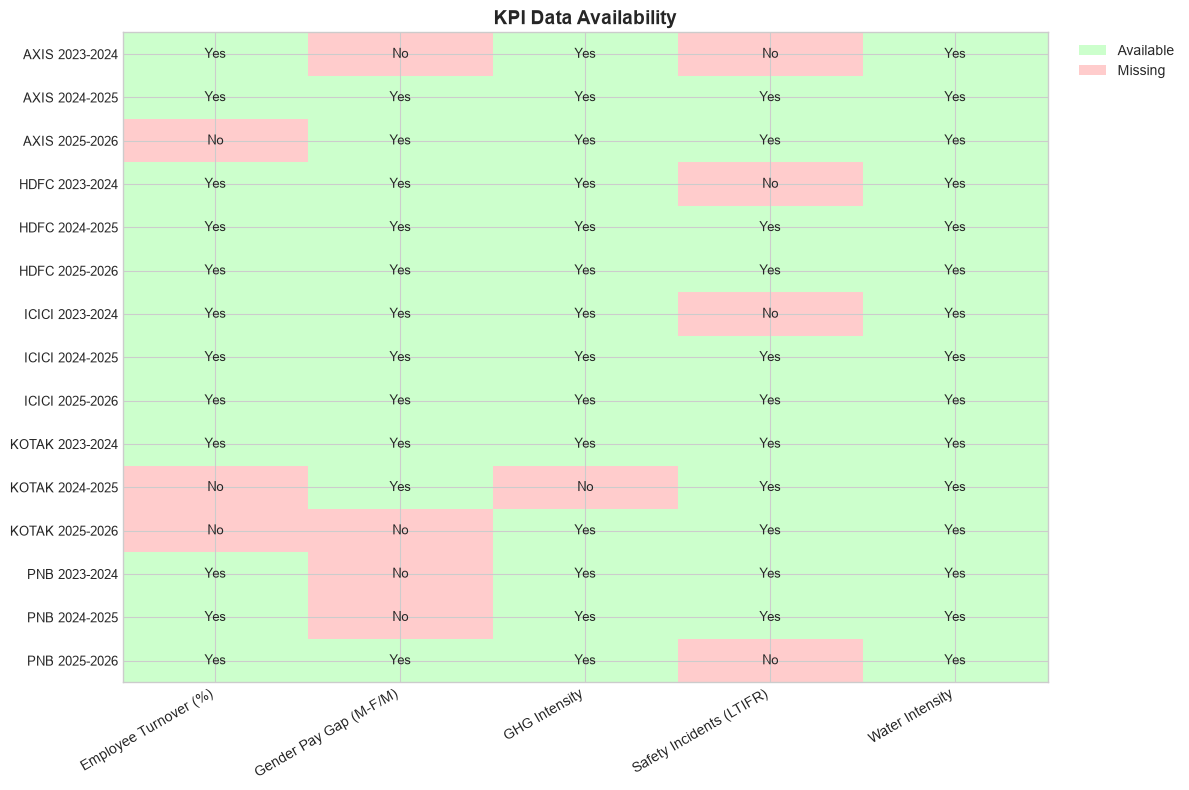

Saved: data/output/availability_matrix.png


In [8]:
# Show which KPIs are available per company-FY
avail = kpi_df.copy()
avail['available'] = avail['value'].notna()
pivot_avail = avail.pivot_table(index=['company', 'fy'], columns='kpi', values='available', aggfunc='first')
pivot_avail = pivot_avail.reindex(pd.MultiIndex.from_product([COMPANY_ORDER, FY_ORDER]))
pivot_avail = pivot_avail.rename(columns=kpi_labels)

fig, ax = plt.subplots(figsize=(12, 8))
cmap = plt.cm.colors.ListedColormap(['#ffcccc', '#ccffcc'])
im = ax.imshow(pivot_avail.values.astype(float), cmap=cmap, aspect='auto')
ax.set_xticks(range(len(pivot_avail.columns)))
ax.set_xticklabels(pivot_avail.columns, fontsize=10, rotation=30, ha='right')
ax.set_yticks(range(len(pivot_avail.index)))
ax.set_yticklabels([f'{c} {fy}' for c, fy in pivot_avail.index], fontsize=9)
ax.set_title('KPI Data Availability', fontsize=14, fontweight='bold')

# Legend
from matplotlib.patches import Patch
ax.legend(handles=[Patch(facecolor='#ccffcc', label='Available'),
                    Patch(facecolor='#ffcccc', label='Missing')],
          loc='upper left', bbox_to_anchor=(1.02, 1))

# Annotate
for i in range(pivot_avail.shape[0]):
    for j in range(pivot_avail.shape[1]):
        v = pivot_avail.values[i, j]
        label = 'Yes' if v == True else ('No' if v == False else '?')
        ax.text(j, i, label, ha='center', va='center', fontsize=9)

plt.tight_layout()
plt.savefig(ROOT / 'data' / 'output' / 'availability_matrix.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved: data/output/availability_matrix.png')